In [1]:
!wget -q -c -O rev1-benchmark-data.tar.gz https://github.com/huboqiang/omnialigner/releases/download/rev1/rev1-benchmark-data.tar.gz
!git clone --quiet --filter=blob:none --sparse --depth 1 --branch rev1 https://github.com/huboqiang/omnialigner.git omnialigner-rev1
!git -C omnialigner-rev1 sparse-checkout set --no-cone /benchmarks/rev1/OmniAligner/ /src/omnialigner/__init__.py /src/omnialigner/plotting/

from pathlib import Path
import hashlib, tarfile, sys
assert (3, 10) <= sys.version_info[:2] < (3, 12), "Use a Python 3.10 or 3.11 Jupyter kernel."
archive = Path("rev1-benchmark-data.tar.gz").resolve()
checkout = Path("omnialigner-rev1").resolve()
assert archive.is_file() and (checkout / ".git").is_dir(), "Download or clone failed; inspect the messages above."
assert hashlib.sha256(archive.read_bytes()).hexdigest() == "9b98464f0b6625bae48514c601b740caee50aeb008525f103a362fc7a630d7d3", "Data archive checksum mismatch"
destination = checkout / "benchmarks/rev1"
with tarfile.open(archive, "r:gz") as bundle:
    for member in bundle.getmembers():
        if member.name == "NCS" or member.name.startswith("NCS/"):
            member.name = "OmniAligner" + member.name[3:]
        target = (destination / member.name).resolve()
        assert target.is_relative_to(destination) and not (member.issym() or member.islnk()), "Unsafe archive member"
    bundle.extractall(destination)
PACKAGE_ROOT = destination / "OmniAligner"
print("Downloaded and verified rev1 data; package:", PACKAGE_ROOT.name)

!wget -q -c -O {checkout.parent / 'rev1-NCS-nine-metric-inputs-20261118-8a91c856ca19edd6.tar.gz'} https://github.com/huboqiang/omnialigner/releases/download/rev1/rev1-NCS-nine-metric-inputs-20261118-8a91c856ca19edd6.tar.gz
sys.path.insert(0, str(checkout / "src"))

In [2]:
import sys
!"{sys.executable}" -m pip install -q numpy==1.26.0 scipy==1.15.3 pandas==2.1.1 anndata==0.10.9 h5py==3.14.0 scikit-learn==1.4.2 matplotlib==3.9.1 seaborn==0.13.2 openpyxl==3.1.5 numba==0.61.2
%cd {PACKAGE_ROOT}

# OmniAligner: NCS nine-metric benchmark

Six datasets, nine algorithm families, and nine endpoints. The first half visibly
recalculates all 44 selected OmniAligner adjacent pairs from the public expression
and coordinate NPZs. The second half adds ARI/NMI/CLC and reconstructs the current
nine-algorithm comparison from verified pair records. Source status and partial
coverage are retained; native missing values are never fabricated.

The raw six-metric values reproduce the released original scoring protocol.
The current fixed-nine failure-credit ranking is a separately labeled derived
quantity. Model fitting is not rerun in this scoring notebook.

MLN PASTE and PASTE2 retain their original native 19 × 5,000-cell evaluation
support (95,000 cells), while full-cell methods retain their documented larger
supports. No full-cell projection is invented. Two audited source corrections are
recorded separately: PASTE MLN now uses its actual `spatial` output rather than an
inherited input field, and PASTE2 E14–16 uses the current frozen cell mask. All 36
selected OmniAligner native endpoint means are retained within declared CPU
rounding tolerances. These results are consistency readouts, not independent
anatomical validation or significance tests.

The release data contain exact original expression values for the frozen evaluation-gene panel, original cell IDs, annotations and raw coordinates, exported losslessly as sparse NPZs. They are sufficient for the scoring computation; full H5AD downloads are linked separately. Input hashes bind the exported arrays to the audited source H5ADs. No benchmark-server directory is required.

## 1. Load the downloaded benchmark inputs
The paths below are relative to the cloned package. All 18 MLN pairs are included. Each dataset is saved after scoring; reference values never fill a missing or failed calculation.

In [3]:
from pathlib import Path
import os, sys, json, csv, hashlib, importlib.metadata, warnings, time
import numpy as np
import pandas as pd
import anndata as ad
import scipy.sparse as sp
from IPython.display import display

def locate_repository():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "notebooks/OmniAligner_NCS_manifest.json").is_file():
            return candidate
    raise FileNotFoundError("Run from this repository or its notebooks directory")
REPO_ROOT = locate_repository()
DATA_ROOT = REPO_ROOT / "data"
INPUT_ROOT = DATA_ROOT
input_records = json.loads((INPUT_ROOT / "evaluation_inputs_manifest.json").read_text())
input_index = {(x["dataset"], x["layer"]): x for x in input_records}
OUTPUT_ROOT = REPO_ROOT / "results" / "omni"
DATASETS = ["DLPFC", "MHPR", "MMPC", "MPC", "E14_16", "MLN"]
VERIFY_SOURCE_HASHES = True
ATOL = 1e-10
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
METRICS = ["PCC", "CosSim", "SSIM", "MI", "MSE", "Region"]
NATIVE_KEYS = ["PCC", "CosSim", "SSIM", "MI", "Expression_MSE_native_ASSD_bygrid", "Accuracy"]
manifest = json.loads((REPO_ROOT / "notebooks/OmniAligner_NCS_manifest.json").read_text())
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(8 * 1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()
def save_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False))
    temporary.replace(path)
reference_path = REPO_ROOT / "notebooks/OmniAligner_NCS_reference.csv"
assert sha256(reference_path) == manifest["expected_table_sha256"]
selected_manifest = manifest
print("Six datasets loaded; expected values will be read after calculation.")

Six datasets loaded; expected values will be read after calculation.


## 2. Verify inputs and the frozen scorer
Hashes bind the exact source H5ADs, selected coordinates, nine checkpoints and original scoring implementation. The six metric directions are PCC/CosSim/SSIM/MI/Region ↑ and MSE ↓. MSE scales differ across datasets; no cross-dataset mean is calculated.

In [4]:
sys.path.insert(0, str(REPO_ROOT / "src"))

assert sha256(REPO_ROOT / manifest["native_scoring_file"]) == manifest["native_scoring_sha256"]
inventory = []
for dataset in DATASETS:
    config = manifest["datasets"][dataset]
    assert sha256(DATA_ROOT / config["coordinates"]) == config["coordinates_sha256"], dataset
    for item in config["weights"]:
        assert sha256(DATA_ROOT / item["path"]) == item["sha256"], item["path"]
    for layer in range(len(config["sections"])):
        record = input_index[(dataset, layer)]
        source = INPUT_ROOT / record["path"]
        assert source.is_file(), source
        assert record["source_h5ad_sha256"] == config["source_sha256"][layer]
        if VERIFY_SOURCE_HASHES:
            assert sha256(source) == record["sha256"], source
    inventory.append({"Dataset": dataset, "Sections": len(config["sections"]), "Pairs": config["pairs"],
                      "Original cells": config["original_cells"], "Scored cells": config["evaluation_cells"],
                      "Gene arguments": len(config["evaluation_genes"]), "Unique genes": len(set(config["evaluation_genes"]))})
display(pd.DataFrame(inventory).set_index("Dataset"))
save_json(OUTPUT_ROOT / "INPUT_VALIDATION.json", {"source_hashes_checked": VERIFY_SOURCE_HASHES, "datasets": DATASETS, "inventory": inventory})

,Sections,Pairs,Original cells,Scored cells,Gene arguments,Unique genes
Dataset,,,,,,
DLPFC,4,3,14243,14243,123,117
MHPR,5,4,28317,28317,155,155
MMPC,3,2,3190,3190,100,100
MPC,3,2,5257,5250,79,79
E14_16,16,15,15295,15150,100,100
MLN,19,18,1097769,1097769,100,100


## Metric calculations, shown explicitly

For every adjacent section pair, `coords` contains the two XY arrays and a shared **10 × 10 overlap grid**. For each gene, `X` contains its two expression vectors. We call the functions below directly: `for metric in [PCC, CosSim, SSIM, MI, MSE]: metric(X, coords)`. `Region(labels, coords)` measures nearest-neighbor regional-label agreement.

| Metric | Calculation |
|---|---|
| PCC ↑ | Pearson correlation between the two vectors of grid-mean expression |
| CosSim ↑ | Dot product divided by the product of vector norms |
| SSIM ↑ | Native luminance × contrast × structure, after separately scaling each vector by its maximum |
| MI ↑ | Native `mutual_info_regression`, with seed 0 reset for each gene |
| MSE ↓ | Mean squared difference between the unscaled grid-mean vectors |
| Region ↑ | Fraction of moving-section labels matching the nearest reference label inside the overlap box |

The grid uses the original half-open bin boundaries and native density threshold. Region uses the original closed overlap bounds. Gene arguments (including repeated names) and adjacent pairs receive equal weights. Missing/nonfinite values are not silently dropped. Native insufficient-grid fallback values remain explicit and are excluded from eligible comparison ranks.

In [5]:
import math
from scipy.stats import pearsonr
from scipy.spatial import cKDTree
from sklearn.feature_selection import mutual_info_regression

### Shared spatial support

In [6]:
def shared_grid(reference_xy, moving_xy):
    """Use the original overlap box, half-open bins and native density threshold."""
    xy = (reference_xy, moving_xy)
    x_min = max(np.min(reference_xy[:, 0]), np.min(moving_xy[:, 0]))
    x_max = min(np.max(reference_xy[:, 0]), np.max(moving_xy[:, 0]))
    y_min = max(np.min(reference_xy[:, 1]), np.min(moving_xy[:, 1]))
    y_max = min(np.max(reference_xy[:, 1]), np.max(moving_xy[:, 1]))
    bins = []
    for i in range(10):
        for j in range(10):
            x_start = x_min + i * (x_max - x_min) / 10
            y_start = y_min + j * (y_max - y_min) / 10
            x_end = x_start + (x_max - x_min) / 10
            y_end = y_start + (y_max - y_min) / 10
            bins.append((x_start, x_end, y_start, y_end))

    def inside(points, box):
        x_start, x_end, y_start, y_end = box
        return ((points[:, 0] >= x_start) & (points[:, 0] < x_end)
                & (points[:, 1] >= y_start) & (points[:, 1] < y_end))

    counts = [[np.sum(inside(points, box)) for box in bins] for points in xy]
    threshold = min(np.mean(counts[0]), np.mean(counts[1])) / 2
    labels = [np.full(len(points), None, dtype=object) for points in xy]
    counter = 1
    for index, box in enumerate(bins):
        keep = counts[0][index] >= threshold and counts[1][index] >= threshold
        name = f"Grid_{counter}" if keep else "NonOverlap"
        for points, values in zip(xy, labels):
            values[inside(points, box)] = name
        if keep:
            counter += 1
    return {"xy": xy, "grid_labels": labels}

### Expression means in the retained bins

In [7]:
def grid_expression(X, coords):
    """Mean expression per retained bin, sorted by the native string grid label."""
    means = []
    for expression, labels in zip(X, coords["grid_labels"]):
        frame = pd.DataFrame({"expression": expression, "grid_label": labels})
        frame = frame[(frame.grid_label != "NonOverlap") & frame.grid_label.notnull()]
        means.append(frame.groupby("grid_label").mean().sort_index()["expression"].to_numpy())
    return means

### 1. Pearson correlation

In [8]:
def PCC(X, coords):
    a, b = grid_expression(X, coords)
    return 0.0 if a.size < 2 or b.size < 2 else pearsonr(a, b).statistic

### 2. Cosine similarity

In [9]:
def CosSim(X, coords):
    a, b = grid_expression(X, coords)
    return 0.0 if a.size < 2 or b.size < 2 else a.dot(b) / (np.linalg.norm(a) * np.linalg.norm(b))

### 3. Structural similarity

In [10]:
def SSIM(X, coords):
    a, b = grid_expression(X, coords)
    if a.size < 2 or b.size < 2:
        return 0.0
    # Native convention: separately divide each gene's grid vector by its maximum.
    a, b = a / a.max(), b / b.max()
    mu_a, mu_b = a.mean(), b.mean()
    sigma_a = np.sqrt(((a - mu_a) ** 2).mean())
    sigma_b = np.sqrt(((b - mu_b) ** 2).mean())
    covariance = ((a - mu_a) * (b - mu_b)).mean()
    C1, C2 = 0.01 ** 2, 0.03 ** 2
    C3 = C2 / 2
    luminance = (2 * mu_a * mu_b + C1) / (mu_a ** 2 + mu_b ** 2 + C1)
    contrast = (2 * sigma_a * sigma_b + C2) / (sigma_a ** 2 + sigma_b ** 2 + C2)
    structure = (covariance + C3) / (sigma_a * sigma_b + C3)
    return luminance * contrast * structure

### 4. Mutual information

In [11]:
def MI(X, coords):
    a, b = grid_expression(X, coords)
    if a.size < 2 or b.size < 2:
        return 0.0
    # Reset the seed as in the frozen scorer, including its jitter convention.
    np.random.seed(0)
    return mutual_info_regression(a.reshape(-1, 1), b)[0]

### 5. Expression mean squared error

In [12]:
def MSE(X, coords):
    a, b = grid_expression(X, coords)
    if a.size < 2 or b.size < 2:
        return 100.0  # Native fallback, excluded from eligible table rankings.
    return np.mean(np.square(a - b))

### 6. Regional-label agreement

In [13]:
def Region(labels, coords):
    """Moving-to-reference nearest-neighbor label agreement in the overlap box."""
    reference_xy, moving_xy = coords["xy"]
    x_min = max(np.min(reference_xy[:, 0]), np.min(moving_xy[:, 0]))
    x_max = min(np.max(reference_xy[:, 0]), np.max(moving_xy[:, 0]))
    y_min = max(np.min(reference_xy[:, 1]), np.min(moving_xy[:, 1]))
    y_max = min(np.max(reference_xy[:, 1]), np.max(moving_xy[:, 1]))
    keep = [((points[:, 0] >= x_min) & (points[:, 0] <= x_max)
             & (points[:, 1] >= y_min) & (points[:, 1] <= y_max))
            for points in (reference_xy, moving_xy)]
    reference_xy, moving_xy = reference_xy[keep[0]], moving_xy[keep[1]]
    reference_labels = np.asarray(labels[0])[keep[0]]
    moving_labels = np.asarray(labels[1])[keep[1]]
    _, neighbors = cKDTree(reference_xy).query(moving_xy)
    if len(neighbors) == 0:
        return 0.0
    matches = sum(reference_labels[target] == moving_labels[index]
                  for index, target in enumerate(neighbors)
                  if target < len(reference_labels) and index < len(moving_labels))
    return matches / len(neighbors)

## 3. Join selected coordinates to original cells
The join uses `s<section index>_<original obs_name>`, with an exact one-to-one identity check. For MPC and E14–16 the saved `historical_cohort` mask reproduces the reported common-cell evaluation; the additional original cells are not silently included. DLPFC preserves 123 gene arguments (117 distinct genes), including the historical multiplicity. All other gene orders are also unchanged.

Coordinates remain in the saved benchmark frame, without rescaling or a physical-micrometre claim. Expression is neither normalised nor otherwise altered here.

In [14]:
def load_scoring_slice(dataset, layer, coordinates):
    config = manifest["datasets"][dataset]
    record = input_index[(dataset, layer)]
    with np.load(INPUT_ROOT / record["path"], allow_pickle=False) as raw:
        matrix = sp.csr_matrix((raw["data"], raw["indices"], raw["indptr"]), shape=tuple(raw["shape"]))
        source = ad.AnnData(X=matrix)
        source.obs_names = raw["ids"].astype(str)
        source.var_names = raw["genes"].astype(str)
        source.obs[config["label_column"]] = raw["labels"].astype(str)
        source.obsm["spatial"] = raw["raw_xy"]
    try:
        wanted = [f"s{layer}_{value}" for value in source.obs_names]
        selected = coordinates["layers"] == layer
        ids = coordinates["ids"][selected].tolist()
        assert len(set(ids)) == len(ids) == len(wanted)
        assert set(ids) == set(wanted), (dataset, layer, "Cell identity mismatch")
        lookup = {value: index for index, value in enumerate(ids)}
        order = np.asarray([lookup[value] for value in wanted])
        xy = coordinates["nonrigid"][selected][order]
        keep = coordinates["historical_cohort"][selected][order] if "historical_cohort" in coordinates.files else np.ones(source.n_obs, dtype=bool)
        assert np.isfinite(xy).all() and xy.shape == (source.n_obs, 2)
        unique_genes = list(dict.fromkeys(config["evaluation_genes"]))
        data = source[keep, unique_genes].copy()
        data.obsm["spatial"] = xy[keep]
        data.obs["Region"] = data.obs[config["label_column"]].astype(str)
        if not sp.issparse(data.X):
            data.X = sp.csr_matrix(data.X)
        return data
    finally:
        if source.isbacked:
            source.file.close()

## 4. Recompute every adjacent pair
For each gene, call the five molecular metric functions shown above with `X` and `coords`; then calculate regional-label agreement separately. Average genes within each pair and give each adjacent pair equal weight. Non-finite values propagate rather than being silently dropped.


In [15]:
recomputed_rows = []
started = time.time()
for dataset in DATASETS:
    config = manifest["datasets"][dataset]
    target = OUTPUT_ROOT / dataset
    target.mkdir(exist_ok=True)
    pair_rows, gene_rows = [], []
    with np.load(DATA_ROOT / config["coordinates"], allow_pickle=False) as coordinates:
        assert len(coordinates["ids"]) == config["original_cells"]
        assert set(coordinates["layers"].tolist()) == set(range(len(config["sections"])))
        reference_slice = load_scoring_slice(dataset, 0, coordinates)
        for pair_index in range(config["pairs"]):
            moving_slice = load_scoring_slice(dataset, pair_index + 1, coordinates)
            reference_section, moving_section = reference_slice, moving_slice
            gene_arguments = config["evaluation_genes"]
            coords = shared_grid(reference_section.obsm["spatial"], moving_section.obsm["spatial"])
            gene_records = []
            for gene_name in gene_arguments:
                X = (reference_section.X[:, reference_section.var_names == gene_name].toarray().squeeze(),
                     moving_section.X[:, moving_section.var_names == gene_name].toarray().squeeze())
                gene_result = {"gene": gene_name}
                for metric, key in zip([PCC, CosSim, SSIM, MI, MSE], NATIVE_KEYS[:5]):
                    np.random.seed(0)
                    with warnings.catch_warnings(record=True) as caught:
                        warnings.simplefilter("always")
                        try:
                            value = float(metric(X, coords))
                            gene_result[key] = value if math.isfinite(value) else None
                            gene_result[key + "_error"] = "" if math.isfinite(value) else "native_nonfinite"
                        except Exception as error:
                            gene_result[key] = None
                            gene_result[key + "_error"] = repr(error)
                    gene_result[key + "_warnings"] = " | ".join(str(w.message) for w in caught)
                gene_records.append(gene_result)

            # Equal gene-argument weights. A missing gene score invalidates that pair mean.
            values = {}
            for key in NATIVE_KEYS[:5]:
                numbers = [row[key] for row in gene_records]
                assert len(numbers) == len(gene_arguments)
                values[key] = math.fsum(numbers) / len(numbers) if all(v is not None and math.isfinite(v) for v in numbers) else None

            labels = (reference_section.obs["Region"].to_numpy(), moving_section.obs["Region"].to_numpy())
            values["Accuracy"] = float(Region(labels, coords))
            valid = [pd.notna(g) & (g != "NonOverlap") for g in coords["grid_labels"]]
            valid_grids = [len(set(g[mask])) for g, mask in zip(coords["grid_labels"], valid)]
            support = {"reference_cells": reference_section.n_obs, "moving_cells": moving_section.n_obs,
                       "reference_covered": int(valid[0].sum()), "moving_covered": int(valid[1].sum()),
                       "reference_valid_grids": valid_grids[0], "moving_valid_grids": valid_grids[1],
                       "native_insufficient_grid_fallback": bool(min(valid_grids) < 2)}
            assert [row["gene"] for row in gene_records] == config["evaluation_genes"]
            pair_rows.append({"Dataset": dataset, "pair_index": pair_index, **values, **support})
            gene_rows.extend({"pair_index": pair_index, "gene_argument_index": index, **row} for index, row in enumerate(gene_records))
            pd.DataFrame(pair_rows).to_csv(target / "pair_metrics.csv", index=False)
            save_json(OUTPUT_ROOT / "PROGRESS.json", {"dataset": dataset, "pairs_done": pair_index + 1, "pairs_expected": config["pairs"]})
            reference_slice = moving_slice
    assert len(pair_rows) == config["pairs"]
    means = {}
    for (display_name, native_key) in zip(METRICS, NATIVE_KEYS):
        numbers = [row[native_key] for row in pair_rows]
        assert len(numbers) == config["pairs"]
        means[display_name] = math.fsum(numbers) / len(numbers) if all(v is not None and math.isfinite(v) for v in numbers) else None
    pd.DataFrame(gene_rows).to_csv(target / "gene_metrics.csv.gz", index=False, compression="gzip")
    save_json(target / "RECOMPUTED.json", {"dataset": dataset, "pairs": config["pairs"], "metrics": means,
                                          "coordinates_sha256": config["coordinates_sha256"], "source_hashes_checked": VERIFY_SOURCE_HASHES})
    recomputed_rows.append({"Dataset": dataset, **means})
    print(f"{dataset}: {config['pairs']}/{config['pairs']} pairs recomputed")
recomputed = pd.DataFrame(recomputed_rows).set_index("Dataset")
recomputed.to_csv(OUTPUT_ROOT / "OmniAligner_NCS_recomputed.csv")
display(recomputed[METRICS].round(6))

DLPFC: 3/3 pairs recomputed


MHPR: 4/4 pairs recomputed


MMPC: 2/2 pairs recomputed


MPC: 2/2 pairs recomputed


E14_16: 15/15 pairs recomputed


MLN: 18/18 pairs recomputed


,PCC,CosSim,SSIM,MI,MSE,Region
Dataset,,,,,,
DLPFC,0.547930,0.783503,0.531970,0.299724,0.127579,0.884759
MHPR,0.540881,0.869558,0.527731,0.252730,1.218373,0.759039
MMPC,0.197483,0.666920,0.193019,0.069390,81.048677,0.871546
MPC,0.333290,0.625865,0.323609,0.152123,0.341752,0.978106
E14_16,0.411842,0.947845,0.414820,0.191671,0.125625,0.643624
MLN,0.812007,0.982588,0.811243,0.809955,0.055572,0.406042


## 5. Compare with the current result table
Each metric is checked separately at absolute tolerance `1e-10`, with no relative tolerance. A mismatch raises an error and leaves the recomputed files available for investigation; it never overwrites the reference table.

Cosine uses float32 dot products; its cross-CPU check allows eight float32 epsilons. Other endpoint tolerances remain 1e-10. Raw source references are unchanged.

In [16]:
reference = pd.read_csv(reference_path, float_precision="round_trip").set_index("Dataset")
expected = reference.loc[DATASETS, METRICS].astype(float)
actual = recomputed.loc[DATASETS, METRICS].astype(float)
difference = actual - expected
tolerances = {metric: (8 * float(np.finfo(np.float32).eps) if metric=="CosSim" else ATOL) for metric in METRICS}
matches = np.column_stack([np.isclose(actual[metric], expected[metric], atol=tolerances[metric], rtol=0, equal_nan=False) for metric in METRICS])
display(difference.rename_axis("Dataset: recomputed minus reference"))
validation = {"all_metrics_match": bool(matches.all()), "datasets": DATASETS,
              "metrics_checked": int(matches.size), "absolute_tolerances": tolerances,
              "maximum_absolute_difference": float(np.abs(difference.to_numpy()).max()),
              "elapsed_seconds": time.time() - started,
              "source_hashes_checked": VERIFY_SOURCE_HASHES,
              "packages": {name: importlib.metadata.version(name) for name in ["numpy", "scipy", "pandas", "anndata", "scikit-learn"]}}
save_json(OUTPUT_ROOT / "VALIDATION.json", validation)
assert matches.all(), "Recomputed metrics differ: inspect pair_metrics.csv and gene_metrics.csv.gz; the reference was not changed."
print(f"PASS: {matches.size}/{matches.size} original metrics match; cosine allows eight float32 epsilons for CPU rounding, all other endpoints use 1e-10.")

,PCC,CosSim,SSIM,MI,MSE,Region
Dataset: recomputed minus reference,,,,,,
DLPFC,0.000000e+00,-1.130711e-08,0.000000e+00,0.000000e+00,-2.775558e-17,0.000000e+00
MHPR,1.110223e-16,9.132970e-10,0.000000e+00,0.000000e+00,4.440892e-16,-1.110223e-16
MMPC,2.775558e-17,-1.039356e-08,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
MPC,0.000000e+00,-1.207183e-08,5.551115e-17,-5.551115e-17,0.000000e+00,0.000000e+00
E14_16,-5.551115e-17,-3.973644e-11,-5.551115e-17,2.775558e-17,0.000000e+00,0.000000e+00
MLN,0.000000e+00,-5.960464e-10,0.000000e+00,0.000000e+00,0.000000e+00,5.551115e-17


PASS: 36/36 original metrics match; cosine allows eight float32 epsilons for CPU rounding, all other endpoints use 1e-10.


## Current nine-metric comparison

The calculations below add ARI, NMI and CLC to PCC, cosine similarity, SSIM, MI,
expression MSE and Region agreement. The explicitly declared algorithm roster
enters every comparison within this benchmark. Native values are kept separately from the derived ranking score.

A verified pair is scored normally. A failed, missing or undefined pair contributes
**zero ranking credit**, while its native value remains NA. All expected adjacent
pairs remain in the denominator: ten sections mean nine pairs; five completed
sections supply four successful pairs and leave five missing pairs. Raw MSE is
never replaced by zero. The status table distinguishes pending work from terminal
failure; a pending snapshot is not a completed benchmark.

In [17]:
ALGORITHMS = ['OmniAligner', 'PASTE', 'PASTE2', 'Spateo', 'SPACEL', 'STalign', 'SANTO', 'SLAT', 'MOSAICField']
N_ALGORITHMS = len(ALGORITHMS)
ALL_METRICS = ['PCC', 'CosSim', 'SSIM', 'MI', 'MSE', 'Region', 'ARI', 'NMI', 'CLC']
COHORTS = {'DLPFC': (4, 'sequencing'), 'MHPR': (5, 'imaging'), 'MMPC': (3, 'imaging'), 'MPC': (3, 'imaging'), 'E14_16': (16, 'sequencing'), 'MLN': (19, 'sequencing')}
EXPECTED_PAIRS = {name: layers - 1 for name, (layers, _) in COHORTS.items()}
CURRENT_ARCHIVE = checkout.parent / Path('rev1-NCS-nine-metric-inputs-20261118-8a91c856ca19edd6.tar.gz')
CURRENT_SHA256 = '6aead9e0ff9b0fc7218ac94e833502798b6dc8acd7f18ef0126897a47824e58c'
assert sha256(CURRENT_ARCHIVE) == CURRENT_SHA256, "Current scoring bundle checksum differs"
CURRENT_ROOT = Path("current_ncs_inputs")
CURRENT_ROOT.mkdir(exist_ok=True)
with tarfile.open(CURRENT_ARCHIVE) as package:
    for member in package.getmembers():
        target = (CURRENT_ROOT / member.name).resolve()
        assert target.is_relative_to(CURRENT_ROOT.resolve()) and not member.issym() and not member.islnk()
    package.extractall(CURRENT_ROOT)
current_manifest = json.loads((CURRENT_ROOT / "manifest.json").read_text())
for item in current_manifest["files"]:
    assert sha256(CURRENT_ROOT / item["path"]) == item["sha256"], item["path"]
status = pd.read_csv(CURRENT_ROOT / "condition_status.csv")
# The archived collector flag covered additional unfinished native jobs.
# Report resolution of this notebook's explicitly declared main roster instead.
status = status.drop(columns=["all_tasks_complete"], errors="ignore")
status["main_scope_resolved"] = ~status.status.astype(str).str.contains(
    "pending|await|unbound|running|scoring_incomplete|adapter", case=False, regex=True)
status["native_fit_complete"] = status.status.eq("complete")
assert status.main_scope_resolved.all(), "Main-scope scoring tasks remain unresolved"
display(status)
print("Snapshot:", current_manifest["snapshot"], "; scope:", current_manifest["scope"])

,dataset,method,status,pairs_completed,pairs_expected,reason,main_scope_resolved,native_fit_complete
0,DLPFC,OmniAligner,complete,3,3,Verified current coordinates and complete score receipt,True,True
1,DLPFC,PASTE,complete,3,3,Verified current coordinates and complete score receipt,True,True
2,DLPFC,PASTE2,complete,3,3,Verified current coordinates and complete score receipt,True,True
3,DLPFC,Spateo,complete,3,3,Verified current coordinates and complete score receipt,True,True
4,DLPFC,SPACEL,complete,3,3,Verified current coordinates and complete score receipt,True,True
5,DLPFC,STalign,complete,3,3,Verified current coordinates and complete score receipt,True,True
6,DLPFC,SANTO,complete,3,3,Verified current coordinates and complete score receipt,True,True
7,DLPFC,SLAT,complete,3,3,Verified current coordinates and complete score receipt,True,True
8,DLPFC,MOSAICField,complete,3,3,Verified current coordinates and complete score receipt,True,True
9,MHPR,OmniAligner,complete,4,4,Verified current coordinates and complete score receipt,True,True


Snapshot: 8a91c856ca19edd6 ; scope: NCS: current source-bound pair scores; explicit complete input-loading gate


### Three visible categorical metrics

ARI and NMI compare saved categorical rasters, including background pixels. The
raster is the same fixed evaluation grid for every method within a cohort; it is
not fitted to each output's bounding box. CLC uses the saved native coordinates
and shared category identities. Its directional nearest-neighbour mapping,
2.5% neighbourhood and self inclusion match the original implementation.
The bounded loop below avoids constructing an entire dense cell-by-cell matrix.

In [18]:
"""Original Figure 2 categorical scores, with bounded-memory CLC evaluation.

The notebook displays this complete implementation. No expression matrix enters
these scores. CLC preserves the historical directional 1-NN fallback and 2.5%
neighbourhood definition; its name in the original source was CLC-MNN.
"""
import numpy as np
from scipy.spatial import KDTree
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from numba import njit


def ari(reference_image, moving_image):
    """Categorical raster ARI, including the background pixels."""
    return float(adjusted_rand_score(reference_image.ravel(), moving_image.ravel()))


def nmi(reference_image, moving_image):
    """Categorical raster NMI, sklearn arithmetic normalization."""
    return float(normalized_mutual_info_score(reference_image.ravel(), moving_image.ravel()))


@njit(cache=False)
def _membership_fraction(mapped_neighbors, target_neighbors):
    """Exact set membership using a reusable integer mark array."""
    n, k = mapped_neighbors.shape
    upper = max(np.max(mapped_neighbors), np.max(target_neighbors)) + 1
    marks = np.zeros(upper, dtype=np.int64)
    result = np.zeros(n)
    for row in range(n):
        stamp = row + 1
        for col in range(k):
            marks[target_neighbors[row, col]] = stamp
        count = 0
        for col in range(k):
            if marks[mapped_neighbors[row, col]] == stamp:
                count += 1
        result[row] = count / k
    return result


def clc(labels_reference, labels_moving, coords_reference, coords_moving, batch_size=256):
    """Directional original CLC, computed in bounded-memory blocks.

    Original MNN code keeps a mutual match when present and falls back to the
    source-to-target 1-NN otherwise. Both branches choose the same target index,
    so the final mapping is the single directional nearest-neighbour query.
    Each source point contributes label agreement times the fraction of its
    mapped neighbours belonging to its target point's own neighbourhood.
    Neighbourhoods include the point itself, exactly as in the original code.
    """
    n1, n2 = len(coords_reference), len(coords_moving)
    k = max(1, int((n1 + n2) / 2 * 2.5 / 100))
    if k > min(n1, n2):
        raise ValueError('Historical neighbourhood exceeds one section size.')
    tree1, tree2 = KDTree(coords_reference), KDTree(coords_moving)
    target_index = tree2.query(coords_reference, k=1)[1]
    agreement = labels_reference == labels_moving[target_index]
    contributions = np.zeros(n1, dtype=np.float64)
    active = np.flatnonzero(agreement)
    for start in range(0, len(active), batch_size):
        rows = active[start:start + batch_size]
        source_neighbors = tree1.query(coords_reference[rows], k=k)[1].reshape(len(rows), k)
        target_neighbors = tree2.query(coords_moving[target_index[rows]], k=k)[1].reshape(len(rows), k)
        mapped_neighbors = target_index[source_neighbors]
        contributions[rows] = _membership_fraction(mapped_neighbors, target_neighbors)
    return float(contributions.mean())

### Recalculate the released example pairs

These small NPZ files contain actual current coordinates, category labels, cell
identities and evaluation rasters. Expected values are consulted only after the
calculation. Full-dataset score records below retain every expected pair and their
source hashes; they are reaggregated rather than described as fresh model fitting.

In [19]:
fresh_examples = []
for item in current_manifest["categorical_examples"]:
    with np.load(CURRENT_ROOT / item["path"], allow_pickle=False) as pair:
        key = (item["dataset"], item["method"], item["pair_index"])
        matching_native = globals().get("fresh_native_input_checks", {}).get(key)
        if matching_native is not None:
            for side in ["reference", "moving"]:
                np.testing.assert_array_equal(pair[side+"_cell_ids"], matching_native[side+"_cell_ids"])
                np.testing.assert_array_equal(pair[side+"_coords"], matching_native[side+"_coords"])
        coords = [pair[side + "_coords"] for side in ["reference", "moving"]]
        labels = [pair[side + "_labels"] for side in ["reference", "moving"]]
        grids = [pair[side + "_raster"] for side in ["reference", "moving"]]
        for side in ["reference", "moving"]:
            assert len(np.unique(pair[side + "_cell_ids"])) == len(pair[side + "_cell_ids"])
        result = {"dataset": item["dataset"], "method": item["method"], "pair_index": item["pair_index"]}
        for func in [ari, nmi]:
            result[func.__name__.upper()] = func(*grids)
        result["CLC"] = clc(*labels, *coords)
    for name in ["ARI", "NMI", "CLC"]:
        np.testing.assert_allclose(result[name], item["expected"][name], rtol=0, atol=1e-10)
    fresh_examples.append(result)
display(pd.DataFrame(fresh_examples))

,dataset,method,pair_index,ARI,NMI,CLC
0,DLPFC,OmniAligner,0,0.354851,0.30427,0.880135


## Optional: recalculate every ARI/NMI/CLC pair from the complete NPZ inputs

The default run above calculates a real example pair and later rebuilds the whole
table from independently verified pair records. Set `FULL_CATEGORICAL_RECALC=True`
to download the complete saved coordinates, labels and categorical rasters and
recalculate all three metrics, with the explicit loops below. Choose one dataset
first if desired. This needs no model fitting, SSH or private folders.

ARI/NMI operate on the released fixed evaluation rasters; CLC uses native saved
coordinates. CLC can take tens of minutes for a large dataset and several hours
for the complete Deep comparison. The complete Deep input archives total about
1.48 GB; the default run does not download them. A confirmed native failure has
no output NPZ and retains raw NA; it is never converted to a synthetic measurement.
Expected scores are consulted only after each newly calculated pair.

Exact CLC references were computed on Linux. Identical coordinates can have
multiple equidistant k-neighbours; different SciPy builds may choose different
members of a boundary tie. The full mode reports these differences separately
and never silently replaces the official table or loosens its tolerance. In the
audited DLPFC case the difference was exactly two neighbourhood members,
`2/(3611×90) = 0.000006154`, with identical coordinates, labels and 1NN matches.
Using the original Linux neighbours recovers the reference exactly.

In [20]:
FULL_CATEGORICAL_RECALC = False
CATEGORICAL_DATASETS = list(COHORTS)  # e.g. ["DLPFC"] for NCS, ["ST_brain"] for Deep.

if FULL_CATEGORICAL_RECALC:
    import subprocess, time
    # Public immutable NPZ URLs/checksums are embedded: no local catalog or new Git commit is required.
    entries = {'DLPFC': {'asset': {'file': 'rev1-NCS-categorical-DLPFC-20261118-936e5e568e17.tar.gz', 'url': 'https://github.com/huboqiang/omnialigner/releases/download/rev1/rev1-NCS-categorical-DLPFC-20261118-936e5e568e17.tar.gz', 'sha256': '5544c4fa6507757ae48d86b944b9d42141076dea983de68586eef223415bce8e', 'bytes': 6196706}, 'archive_prefix': ''}, 'MHPR': {'asset': {'file': 'rev1-NCS-categorical-MHPR-20261118-c4be1de664fd.tar.gz', 'url': 'https://github.com/huboqiang/omnialigner/releases/download/rev1/rev1-NCS-categorical-MHPR-20261118-c4be1de664fd.tar.gz', 'sha256': 'e611574658048d6c3bd2c1fd01813598304469927d1423f67f0b175b58b5a18d', 'bytes': 9030886}, 'archive_prefix': ''}, 'MMPC': {'asset': {'file': 'rev1-NCS-categorical-MMPC-20261118-bed2275f0934.tar.gz', 'url': 'https://github.com/huboqiang/omnialigner/releases/download/rev1/rev1-NCS-categorical-MMPC-20261118-bed2275f0934.tar.gz', 'sha256': '491f30dd74f6355b0191d0dbc52d984d33953369a5d1f38587fdb428641078a5', 'bytes': 1704685}, 'archive_prefix': ''}, 'MPC': {'asset': {'file': 'rev1-NCS-categorical-MPC-20261118-d31287e8a831.tar.gz', 'url': 'https://github.com/huboqiang/omnialigner/releases/download/rev1/rev1-NCS-categorical-MPC-20261118-d31287e8a831.tar.gz', 'sha256': '1c3075df178e23d70b04bd599d4242e1fbdd19c200124b59eb10fc079256586a', 'bytes': 2543644}, 'archive_prefix': ''}, 'E14_16': {'asset': {'file': 'rev1-NCS-categorical-E14_16-20261118-a749a6984d82.tar.gz', 'url': 'https://github.com/huboqiang/omnialigner/releases/download/rev1/rev1-NCS-categorical-E14_16-20261118-a749a6984d82.tar.gz', 'sha256': '35c0d3116a5cf0b27effd7e808b99a661b72f65643ab6dee66fd03ffa5a9c0dd', 'bytes': 9917161}, 'archive_prefix': ''}, 'MLN': {'asset': {'file': 'rev1-NCS-categorical-MLN-20261118-cec8bc7eb154.tar.gz', 'url': 'https://github.com/huboqiang/omnialigner/releases/download/rev1/rev1-NCS-categorical-MLN-20261118-cec8bc7eb154.tar.gz', 'sha256': 'e0d3473330a76ee82507e482548cb479d2cf041b853a0e2206dc065388a541d8', 'bytes': 302785965}, 'archive_prefix': ''}}
    assert set(CATEGORICAL_DATASETS) <= set(COHORTS)
    expected_categories = pd.read_csv(CURRENT_ROOT / "observed_pair_metrics.csv", float_precision="round_trip")
    recalculated_categories = []
    categorical_comparison = []
    full_started = time.perf_counter()

    def calculate_categorical_pair(grids, labels, xy):
        # These are the actual metric functions displayed above, not an imported scorer.
        values = {}
        for func in [ari, nmi]:
            values[func.__name__.upper()] = func(np.asarray(grids[0]).squeeze(), np.asarray(grids[1]).squeeze())
        values["CLC"] = clc(labels[0], labels[1], xy[0], xy[1])
        return values

    def keep_verified_pair(dataset, method, pair_index, values):
        for metric, value in values.items():
            expected = expected_categories.loc[
                expected_categories.dataset.eq(dataset) & expected_categories.method.eq(method)
                & expected_categories.pair_index.eq(pair_index) & expected_categories.metric.eq(metric)]
            assert len(expected)==1, "Expected pair key absent or duplicated"
            reference_value=float(expected.raw_value.iloc[0])
            exact=bool(np.isclose(value,reference_value,rtol=0,atol=1e-10))
            categorical_comparison.append(dict(dataset=dataset,method=method,pair_index=pair_index,
                metric=metric,calculated=value,reference=reference_value,difference=value-reference_value,
                matches_native_reference=exact))
            if metric!="CLC":
                np.testing.assert_allclose(value,reference_value,rtol=0,atol=1e-10)
        row = dict(dataset=dataset, method=method, pair_index=pair_index, **values)
        recalculated_categories.append(row)
        print(f"{dataset} / {method} / pair {pair_index+1}/{EXPECTED_PAIRS[dataset]}:",
              {name:round(value,6) for name,value in values.items()})

    for dataset in CATEGORICAL_DATASETS:
        item = entries[dataset]
        payload = Path("full_categorical_downloads") / item["asset"]["file"]
        payload.parent.mkdir(exist_ok=True)
        subprocess.run(["wget", "-q", "-c", "-O", str(payload), item["asset"]["url"]], check=True)
        assert sha256(payload)==item["asset"]["sha256"], "Complete input archive checksum differs"
        expanded = payload.parent / dataset
        expanded.mkdir(exist_ok=True)
        with tarfile.open(payload) as bundle:
            for member in bundle.getmembers():
                target=(expanded/member.name).resolve()
                assert target.is_relative_to(expanded.resolve()) and not member.issym() and not member.islnk()
            bundle.extractall(expanded)
        inputs = expanded / item.get("archive_prefix", "")
        saved_manifest = json.loads((inputs / "manifest.json").read_text())
        methods = []
        for source in saved_manifest["records"]:
            if source["status"]=="native_failed":
                methods.append(dict(method=source["method"], kind="unavailable", status="native_failed"))
            elif "inputs" in source:
                if source.get("representation", "").startswith("per_pair"):
                    methods.append(dict(method=source["method"], kind="pairs",
                        pairs=[dict(pair_index=p["pair_index"],file=p["path"],sha256=p["sha256"]) for p in source["inputs"]]))
                else:
                    one=source["inputs"][0]
                    methods.append(dict(method=source["method"],kind="global",file=one["path"],sha256=one["sha256"]))
            else:
                methods.append(dict(method=source["method"],kind="global",file=source["file"],sha256=source["sha256"]))
        for record in methods:
            method = record["method"]
            if method not in ALGORITHMS:
                continue
            if record["kind"]=="unavailable":
                assert record["status"]=="native_failed", "Unresolved input must not be scored as a failure"
                print(dataset, method, ": confirmed native failure; no coordinate NPZ exists; raw NA retained.")
                continue
            if record["kind"]=="global":
                path=inputs/record["file"]
                assert sha256(path)==record["sha256"]
                with np.load(path,allow_pickle=False) as saved:
                    layers=saved["layers"]; labels=saved["labels"]; xy=saved["coords"]
                    grids=saved["raster"]; ids=saved["cell_ids"]
                    assert len(np.unique(ids))==len(ids)
                    order=np.unique(layers)
                    assert len(order)-1==EXPECTED_PAIRS[dataset]
                    for pair_index,(left,right) in enumerate(zip(order[:-1],order[1:])):
                        selections=[layers==left,layers==right]
                        values=calculate_categorical_pair([grids[pair_index],grids[pair_index+1]],
                            [labels[mask] for mask in selections],[xy[mask] for mask in selections])
                        keep_verified_pair(dataset,method,pair_index,values)
                del layers,labels,xy,grids,ids
            elif record["kind"]=="pairs":
                assert len(record["pairs"])==EXPECTED_PAIRS[dataset]
                for pair in record["pairs"]:
                    path=inputs/pair["file"]
                    assert sha256(path)==pair["sha256"]
                    with np.load(path,allow_pickle=False) as saved:
                        xy=[saved[side+"_coords"] for side in ["reference","moving"]]
                        labels=[saved[side+"_labels"] for side in ["reference","moving"]]
                        grids=[saved[side+"_raster"] for side in ["reference","moving"]]
                        values=calculate_categorical_pair(grids,labels,xy)
                    keep_verified_pair(dataset,method,int(pair["pair_index"]),values)
            else:
                raise ValueError("Unknown complete-input layout: "+record["kind"])
    freshly_recomputed=pd.DataFrame(recalculated_categories)
    freshly_recomputed.to_csv(CURRENT_ROOT/"FULL_fresh_categorical_pair_scores.csv",index=False)
    # These fresh values will enter the later table, after exact source-key checks.
    comparison=pd.DataFrame(categorical_comparison)
    comparison.to_csv(CURRENT_ROOT/"FULL_comparison_to_native_reference.csv",index=False)
    all_match=bool(comparison.matches_native_reference.all())
    if all_match:
        fresh_by_key={(row["dataset"],row["method"],row["pair_index"]):row for row in fresh_examples+recalculated_categories}
        fresh_examples=list(fresh_by_key.values())
    else:
        print("CLC build/tie-choice differences are recorded in FULL_comparison_to_native_reference.csv.")
        print("Fresh full-run scores are exported separately; the official reference table is retained.")
    print("All full-run values match the native reference:",all_match)
    print("Full recalculation finished:", len(freshly_recomputed), "pairs; seconds:",round(time.perf_counter()-full_started,1))
else:
    print("Fast run: a real example is recalculated; all other pair records are reaggregated.")
    print("Set FULL_CATEGORICAL_RECALC=True to calculate the full ARI/NMI/CLC experiment from NPZ.")


Fast run: a real example is recalculated; all other pair records are reaggregated.
Set FULL_CATEGORICAL_RECALC=True to calculate the full ARI/NMI/CLC experiment from NPZ.


### Pair coverage, fixed denominator and zero-credit failures

No mean is taken over successful pairs alone. Algorithm configurations are frozen
for each dataset and endpoint before this aggregation; configurations cannot be
switched from pair to pair. `raw_complete_mean` is present only when every expected
pair is eligible. `observed_pair_mean` describes successful observations alone and
is never substituted for the complete score.

Eligible pair values are mapped onto one shared affine quality scale per dataset
and metric: `(value − minimum)/(maximum − minimum)`, reversed for MSE. The bounds
are shared across all eligible pairs and algorithms, never fitted per method.
A constant eligible metric receives quality one. Missing or failed pairs receive
quality zero. This preserves the native-mean ordering of complete experiments;
averaging pair ranks would change that ordering and is deliberately not used. Endpoint credit is the sum of all pair
qualities divided by the complete expected pair count. Endpoint ranks use these coverage-adjusted qualities. Grouped figures then
average `(N − endpoint rank)/(N − 1)` with equal dataset and endpoint weights.

In [21]:
"""Aggregate real native pair scores; missing pairs receive derived zero credit only.

A common affine metric scale preserves the native-mean ordering of fully scored
methods. Averaging pair ranks would change that ordering and is not used here.
"""
import math
import numpy as np
import pandas as pd


def aggregate_pair_scores(observed, expected_pairs, algorithms):
    """Return explicit pair credits and dataset endpoint summaries.

    One frozen configuration per dataset/method/endpoint is required. Native raw
    missing values remain NA. Bounds are shared across every eligible pair and
    algorithm within one dataset/metric, never adjusted separately per method.
    For higher-is-better metrics, quality=(value-min)/(max-min); for MSE it is
    (max-value)/(max-min). A constant eligible metric receives quality 1.
    Missing or ineligible pairs receive quality 0. The full expected pair count
    is always the averaging denominator. Complete methods therefore retain their
    native-mean ordering; partial methods receive an explicit coverage penalty.
    """
    keys = ['dataset', 'method', 'metric', 'pair_index']
    if observed.duplicated(keys).any():
        raise ValueError('Duplicate pair scores: freeze the representative configuration first')
    metrics = list(observed.metric.unique())
    n = len(algorithms)
    index = pd.MultiIndex.from_tuples([
        (ds, method, metric, pair)
        for ds, count in expected_pairs.items() for method in algorithms
        for metric in metrics for pair in range(count)], names=keys)
    if not observed.set_index(keys).index.isin(index).all():
        raise ValueError('Pair, method or dataset outside the declared scoring scope')
    scores = observed.set_index(keys).reindex(index).reset_index()
    scores['eligible'] = scores.eligible.fillna(False).astype(bool) & np.isfinite(scores.raw_value)
    scores['rank_score'] = 0.0
    scores['rank'] = n
    scores['metric_min'] = np.nan
    scores['metric_max'] = np.nan
    # Rank each pair for transparent diagnostics; these ranks are not averaged.
    for (_, metric, _), group in scores.groupby(['dataset', 'metric', 'pair_index'], sort=False):
        valid = group.loc[group.eligible]
        scores.loc[valid.index, 'rank'] = valid.raw_value.rank(method='min', ascending=metric == 'MSE')
    # One common affine quality scale per dataset/metric preserves complete means.
    for (_, metric), group in scores.groupby(['dataset', 'metric'], sort=False):
        valid = group.loc[group.eligible]
        if not len(valid):
            continue
        low, high = float(valid.raw_value.min()), float(valid.raw_value.max())
        scores.loc[group.index, 'metric_min'] = low
        scores.loc[group.index, 'metric_max'] = high
        if high == low:
            quality = np.ones(len(valid))
        elif metric == 'MSE':
            quality = (high - valid.raw_value) / (high - low)
        else:
            quality = (valid.raw_value - low) / (high - low)
        scores.loc[valid.index, 'rank_score'] = quality
    scores['penalized'] = ~scores.eligible
    records = []
    for (ds, method, metric), group in scores.groupby(['dataset', 'method', 'metric'], sort=False):
        count = expected_pairs[ds]
        valid = group.loc[group.eligible]
        assert len(group) == count
        native_mean = math.fsum(valid.raw_value.tolist()) / len(valid) if len(valid) else np.nan
        records.append(dict(dataset=ds, method=method, metric=metric,
            expected_pairs=count, scored_pairs=len(valid), missing_pairs=count-len(valid),
            rank_score=math.fsum(group.rank_score.tolist()) / count,
            raw_complete_mean=native_mean if len(valid) == count else np.nan,
            observed_pair_mean=native_mean, denominator_algorithms=n,
            metric_min=group.metric_min.iloc[0], metric_max=group.metric_max.iloc[0],
            score_kind='coverage_adjusted_native_metric_quality'))
    means = pd.DataFrame(records)
    means['rank'] = n
    means['native_complete_rank'] = np.nan
    for (_, metric), group in means.groupby(['dataset', 'metric'], sort=False):
        means.loc[group.index, 'rank'] = group.rank_score.rank(method='min', ascending=False)
        full = group.loc[group.scored_pairs.eq(group.expected_pairs)]
        means.loc[full.index, 'native_complete_rank'] = full.raw_complete_mean.rank(
            method='min', ascending=metric == 'MSE')
        if len(full) > 1:
            # For completely scored methods, an affine common scale cannot reverse native order.
            ordered = full.sort_values('raw_complete_mean', ascending=metric == 'MSE')
            assert np.all(np.diff(ordered.rank_score.to_numpy()) <= 1e-12), 'Complete native mean ordering changed'
    means.loc[means.scored_pairs.eq(0), 'rank'] = n
    means['normalized_rank_credit'] = (n-means['rank'])/(n-1)
    scores['metric_quality'] = scores['rank_score']
    return scores, means

In [22]:
# Missing input files are not registration failures. Never rank an unloaded table.
assert current_manifest.get("ranking_input_complete", False), (
    "The score snapshot is still being assembled. Existing score sources must all "
    "be loaded and pending conditions resolved before exporting this ranking. "
    "See condition_status.csv; no missing source is assigned a failure rank.")
observed = pd.read_csv(CURRENT_ROOT / "observed_pair_metrics.csv", float_precision="round_trip")
observed = observed.loc[observed.dataset.isin(COHORTS) & observed.method.isin(ALGORITHMS)].copy()
observed["eligible"] = observed.eligible.astype(str).str.lower().eq("true")
# Fresh calculations must correspond to the same released pair records, then enter the table.
for calculated in fresh_examples + globals().get("fresh_native_examples", []):
    for metric in ALL_METRICS:
        if metric not in calculated:
            continue
        match = (observed.dataset.eq(calculated["dataset"]) & observed.method.eq(calculated["method"])
                 & observed.pair_index.eq(calculated["pair_index"]) & observed.metric.eq(metric))
        assert match.sum()==1, "Fresh pair is absent from, or duplicated in, the source comparison"
        np.testing.assert_allclose(observed.loc[match,"raw_value"].iloc[0], calculated[metric], rtol=0,
            atol=8*np.finfo(np.float32).eps if metric=="CosSim" else 1e-10)
        observed.loc[match,"raw_value"] = calculated[metric]
assert set(observed.metric) <= set(ALL_METRICS)
# Include missing endpoints explicitly, even if no method has a finite observation.
for metric in ALL_METRICS:
    if metric not in set(observed.metric):
        observed.loc[len(observed)] = dict(dataset=next(iter(COHORTS)), method=ALGORITHMS[0],
            metric=metric, pair_index=0, raw_value=np.nan, eligible=False)
# Use all 44 freshly recalculated selected OmniAligner pairs in the current table.
for dataset in DATASETS:
    pairs = pd.read_csv(OUTPUT_ROOT / dataset / "pair_metrics.csv", float_precision="round_trip")
    for _, pair in pairs.iterrows():
        for metric, native_key in zip(METRICS, NATIVE_KEYS):
            match = (observed.dataset.eq(dataset) & observed.method.eq("OmniAligner")
                     & observed.pair_index.eq(int(pair.pair_index)) & observed.metric.eq(metric))
            assert match.sum()==1
            np.testing.assert_allclose(observed.loc[match,"raw_value"].iloc[0], pair[native_key], rtol=0,
                atol=8*np.finfo(np.float32).eps if metric=="CosSim" else 1e-10)
            observed.loc[match,"raw_value"] = pair[native_key]
pair_scores, endpoint_scores = aggregate_pair_scores(observed, EXPECTED_PAIRS, ALGORITHMS)
assert len(pair_scores) == sum(EXPECTED_PAIRS.values()) * len(ALGORITHMS) * len(ALL_METRICS)
assert pair_scores.loc[pair_scores.penalized, "rank_score"].eq(0).all()
assert pair_scores.loc[pair_scores.penalized, "rank"].eq(N_ALGORITHMS).all()
assert endpoint_scores.denominator_algorithms.eq(N_ALGORITHMS).all()
# Verify the partial-completion rule independently: 5 of 10 layers gives 4/9, not 5/10.
example = pd.DataFrame([dict(dataset="ten_layers",method="OmniAligner",metric="PCC",
    pair_index=i,raw_value=1.,eligible=True) for i in range(4)])
_, partial_check = aggregate_pair_scores(example, {"ten_layers":9}, ALGORITHMS)
assert np.isclose(partial_check.loc[partial_check.method.eq("OmniAligner"),"rank_score"].iloc[0], 4/9)
assert partial_check.loc[partial_check.method.eq("OmniAligner"),"raw_complete_mean"].isna().all()
wide_scores = endpoint_scores.pivot(index=["dataset","method"], columns="metric", values="rank_score").reindex(columns=ALL_METRICS)
wide_raw = endpoint_scores.pivot(index=["dataset","method"], columns="metric", values="raw_complete_mean").reindex(columns=ALL_METRICS)
display(wide_raw.round(6))
display(wide_scores.round(4))

metric                    PCC    CosSim      SSIM        MI         MSE  \
dataset method                                                            
DLPFC   MOSAICField  0.293491  0.681699  0.286240  0.128547    0.273680   
        OmniAligner  0.547930  0.783503  0.531970  0.299724    0.127579   
        PASTE        0.544071  0.778515  0.528263  0.306357    0.125379   
        PASTE2       0.543163  0.781307  0.528125  0.304160    0.127796   
        SANTO        0.406315  0.723795  0.396180  0.177750    0.203190   
        SLAT         0.536767  0.778471  0.521766  0.298667    0.133502   
        SPACEL       0.542308  0.780266  0.525264  0.298687    0.120631   
        STalign      0.531650  0.780250  0.515869  0.269830    0.144726   
        Spateo       0.546341  0.782310  0.531753  0.297182    0.126346   
E14_16  MOSAICField  0.182823  0.914408  0.194066  0.089574    0.211897   
        OmniAligner  0.411842  0.947845  0.414820  0.191671    0.125625   
        PASTE        0.382526  0.944291  0.386579  0.162621    0.136930   
        PASTE2       0.395308  0.943575  0.398373  0.173266    0.136464   
        SANTO        0.321615  0.935610  0.327376  0.128812    0.157290   
        SLAT         0.389036  0.944710  0.392797  0.165479    0.135331   
        SPACEL       0.409362  0.945594  0.411990  0.192494    0.131897   
        STalign      0.385493  0.944777  0.389318  0.166618    0.134542   
        Spateo       0.398202  0.943851  0.401402  0.180635    0.134154   
MHPR    MOSAICField  0.223893  0.768569  0.222221  0.086066    3.310994   
        OmniAligner  0.540881  0.869558  0.527731  0.252730    1.218373   
        PASTE        0.014652  0.733618  0.026673  0.046316    4.015312   
        PASTE2       0.521702  0.861287  0.509315  0.243140    1.393879   
        SANTO             NaN       NaN       NaN       NaN         NaN   
        SLAT         0.510049  0.857475  0.497675  0.231305    1.490035   
        SPACEL       0.528168  0.863517  0.515406  0.241713    1.307417   
        STalign           NaN       NaN       NaN       NaN         NaN   
        Spateo       0.535648  0.866232  0.521511  0.249683    1.281545   
MLN     MOSAICField  0.671677  0.960303  0.671442  0.464766    0.082297   
        OmniAligner  0.812007  0.982588  0.811243  0.809955    0.055572   
        PASTE        0.389123  0.919561  0.396318  0.239646    0.124499   
        PASTE2       0.668936  0.961677  0.667826  0.430011    0.077474   
        SANTO        0.531558  0.939827  0.528887  0.306617    0.108158   
        SLAT         0.628273  0.955256  0.630293  0.410136    0.085370   
        SPACEL       0.810401  0.981903  0.807871  0.797399    0.056288   
        STalign           NaN       NaN       NaN       NaN         NaN   
        Spateo       0.813540  0.980730  0.810787  0.734435    0.055805   
MMPC    MOSAICField  0.128647  0.591948  0.129254  0.049071  101.993291   
        OmniAligner  0.197483  0.666920  0.193019  0.069390   81.048677   
        PASTE        0.172212  0.650976  0.170476  0.067978   81.590440   
        PASTE2            NaN       NaN       NaN       NaN         NaN   
        SANTO        0.099983  0.606989  0.104715  0.045556   93.775101   
        SLAT         0.183108  0.655952  0.181560  0.064057   79.690503   
        SPACEL       0.188059  0.655706  0.183758  0.062148   83.686211   
        STalign      0.185367  0.659121  0.183038  0.068431   73.721764   
        Spateo       0.196813  0.650570  0.193469  0.074164   80.436955   
MPC     MOSAICField       NaN       NaN       NaN  0.056518    0.706603   
        OmniAligner  0.333290  0.625865  0.323609  0.152123    0.341752   
        PASTE             NaN       NaN       NaN  0.094561    0.425662   
        PASTE2            NaN       NaN       NaN  0.150197    0.322072   
        SANTO             NaN       NaN       NaN  0.066437    0.736596   
        SLAT         0.328565  0.620633  0.318288  0.145316    0.344068   
        SPACEL       0.31

metric                  PCC  CosSim    SSIM      MI     MSE  Region     ARI  \
dataset method                                                                
DLPFC   MOSAICField  0.3229  0.3703  0.3179  0.2204  0.2098  0.1637  0.3017   
        OmniAligner  0.9578  0.8974  0.9508  0.8976  0.6898  0.9585  0.5010   
        PASTE        0.9482  0.8716  0.9413  0.9238  0.6970  0.8791  0.5792   
        PASTE2       0.9459  0.8861  0.9409  0.9151  0.6891  0.9192  0.6454   
        SANTO        0.6044  0.5883  0.6011  0.4150  0.4414  0.2861  0.2196   
        SLAT         0.9300  0.8714  0.9246  0.8934  0.6703  0.8714  0.5405   
        SPACEL       0.9438  0.8807  0.9336  0.8935  0.7126  0.9380  0.7161   
        STalign      0.9172  0.8806  0.9094  0.7793  0.6335  0.7567  0.6301   
        Spateo       0.9539  0.8913  0.9503  0.8875  0.6938  0.8718  0.7064   
E14_16  MOSAICField  0.3995  0.4043  0.3978  0.2122  0.5526  0.3251  0.1703   
        OmniAligner  0.7548  0.7621  0.7502  0.6056  0.8282  0.7455  0.7421   
        PASTE        0.7093  0.7241  0.7051  0.4937  0.7921  0.6214  0.2232   
        PASTE2       0.7291  0.7164  0.7240  0.5347  0.7936  0.6752  0.2445   
        SANTO        0.6148  0.6312  0.6106  0.3634  0.7270  0.4772  0.1602   
        SLAT         0.7194  0.7286  0.7150  0.5047  0.7972  0.6464  0.1994   
        SPACEL       0.7509  0.7381  0.7457  0.6088  0.8082  0.7321  0.2073   
        STalign      0.7139  0.7293  0.7095  0.5091  0.7997  0.6412  0.2439   
        Spateo       0.7336  0.7194  0.7288  0.5631  0.8010  0.6965  0.2378   
MHPR    MOSAICField  0.4360  0.3460  0.4290  0.1921  0.3297  0.4522  0.7913   
        OmniAligner  0.9782  0.9693  0.9764  0.9365  0.9716  0.9534  0.9892   
        PASTE        0.0781  0.1303  0.0786  0.0145  0.1137  0.0861  0.8599   
        PASTE2       0.9454  0.9182  0.9434  0.8937  0.9178  0.9269  0.9888   
        SANTO        0.1510  0.1193  0.1507  0.0709  0.1230  0.1593  0.2321   
        SLAT         0.9254  0.8947  0.9225  0.8408  0.8883  0.9121  0.9945   
        SPACEL       0.9564  0.9320  0.9543  0.8873  0.9443  0.9433  0.9817   
        STalign      0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0002   
        Spateo       0.9692  0.9488  0.9652  0.9229  0.9522  0.9449  0.9774   
MLN     MOSAICField  0.8176  0.8431  0.8187  0.4231  0.7103  0.4704  0.9325   
        OmniAligner  0.9211  0.9467  0.9245  0.7700  0.8153  0.7673  0.8624   
        PASTE        0.6091  0.6537  0.6104  0.1969  0.5446  0.3275  0.5716   
        PASTE2       0.8156  0.8495  0.8159  0.3882  0.7293  0.5202  0.6234   
        SANTO        0.7142  0.7479  0.7108  0.2642  0.6088  0.3469  0.6629   
        SLAT         0.7856  0.8197  0.7875  0.3682  0.6982  0.4157  0.8383   
        SPACEL       0.9199  0.9435  0.9219  0.7574  0.8124  0.7681  0.8207   
        STalign      0.0591  0.0873  0.0599  0.0031  0.0225  0.0149  0.1668   
        Spateo       0.9223  0.9381  0.9241  0.6941  0.8143  0.6985  0.8160   
MMPC    MOSAICField  0.4251  0.4483  0.4164  0.2510  0.4054  0.1029  0.3395   
        OmniAligner  0.7899  0.9505  0.7821  0.6073  0.6841  0.8714  0.9033   
        PASTE        0.6560  0.8437  0.6528  0.5826  0.6768  0.7394  0.7953   
        PASTE2       0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000   
        SANTO        0.2732  0.5491  0.2757  0.1894  0.5147  0.4093  0.5677   
        SLAT         0.7137  0.8770  0.7164  0.5138  0.7021  0.7486  0.7335   
        SPACEL       0.7399  0.8754  0.7290  0.4803  0.6490  0.9659  0.7269   
        STalign      0.7257  0.8983  0.7248  0.5905  0.7815  0.6558  0.8418   
        Spateo       0.7863  0.8410  0.7847  0.6910  0.6922  0.9368  0.7941   
MPC     MOSAICField  0.1843  0.0000  0.1788  0.0773  0.3278  0.2537  0.1683   
        OmniAligner  0.8715  0.6814  0.8684  0.8576  0.9203  0.9952  0.9634   
        PASTE        0.3467  0.2344  0.3548  0.3878  0.7840  0.7740  0.7534   
        PASTE2       0.3769  0.3298  0.3760  0.841

### Publication figures and source tables

Green denotes first place; all other dataset-specific ranks are gray. The summary
uses larger, lighter symbols for better normalized rank credit. Source CSVs retain
native NA, the number of successful/expected pairs, derived credit, and status.
Confirmed failures remain visible rather than becoming fabricated native
measurements. Pending or unloaded sources block final ranking export. All plots use `om.pl.plt`, Arial and editable Type 42 PDF text.

In [23]:
import omnialigner as om
from IPython.display import Image, display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch
om.pl.plt.rcParams.update({"font.family":"Arial", "font.size":7, "pdf.fonttype":42,
    "ps.fonttype":42, "svg.fonttype":"none", "axes.spines.top":False,
    "axes.spines.right":False, "legend.frameon":False})

def draw_current_figures(values, cohorts, algorithms, metrics, output, title, complete=False):
    suffix = "" if complete else " · incomplete snapshot"
    denominator = len(algorithms)
    dataset_names={"ST_brain":"ST brain","E9_5":"E9.5","E14_16":"E14–16"}
    display_names={"CosSim":"Cosine", "Region":"Region", "MSE":"MSE"}
    n=len(cohorts)
    fig,axes=om.pl.plt.subplots((n+1)//2,2,figsize=(7.2,2.05*((n+1)//2)),squeeze=False)
    for panel, ((ds,(layers,technology)),ax) in enumerate(zip(cohorts.items(),axes.ravel())):
        ax.set(xlim=(-2.05,len(metrics)-.45),ylim=(len(algorithms)-.45,-1.1));ax.axis("off")
        ax.set_title(f"{chr(97+panel)}  {dataset_names.get(ds,ds)} · {layers} sections",loc="left",weight="bold",fontsize=8,pad=10)
        for j,metric in enumerate(metrics):
            ax.text(j,-.7,display_names.get(metric,metric)+(" ↓" if metric=="MSE" else " ↑"),ha="center",fontsize=5.4)
        for i,method in enumerate(algorithms):
            ax.text(-.72,i,method,ha="right",va="center",fontsize=6,weight="bold" if method=="OmniAligner" else "normal")
            for j,metric in enumerate(metrics):
                row=values.loc[values.dataset.eq(ds)&values.method.eq(method)&values.metric.eq(metric)].iloc[0]
                first=int(row["rank"])==1
                patch=FancyBboxPatch((j-.44,i-.30),.88,.6,boxstyle="round,pad=0.01,rounding_size=.04",
                    facecolor="#D0E7DB" if first else "#EDF0F2",edgecolor="#75A88F" if first else "#ABB6BF",linewidth=.4)
                ax.add_patch(patch)
                ax.text(j,i,f"{int(row['rank'])}/{denominator}",ha="center",va="center",fontsize=6,
                    color="#205B41" if first else "#344856",weight="bold" if first else "normal")
    for ax in axes.ravel()[n:]:ax.axis("off")
    fig.suptitle(title+": dataset-specific nine-metric ranks"+suffix,x=.03,ha="left",weight="bold",fontsize=10)
    fig.text(.03,.012,"Green: rank 1. Gray: other ranks. Missing/failed pairs: zero credit; native values stay NA. Fixed declared algorithm denominator.",fontsize=5.6,color="#53616A")
    fig.tight_layout(rect=[0,.04,1,.96],h_pad=2.2,w_pad=1.8)
    for extension in ["pdf","svg","png"]:fig.savefig(output/f"{title}_dataset_nine_metric_ranks.{extension}",dpi=240)
    display(Image(filename=str(output / f"{title}_dataset_nine_metric_ranks.png")))
    om.pl.plt.close(fig)
    groups={label:[ds for ds,(_,group) in cohorts.items() if group==kind]
            for kind,label in [("sequencing","Sequencing-based ST"),("imaging","Imaging-based ST")]}
    fig,axes=om.pl.plt.subplots(len(groups),1,figsize=(7.2,6.7),squeeze=False)
    blue=LinearSegmentedColormap.from_list("rank_blue",["#1D6395","#E6F0F4"])
    green=LinearSegmentedColormap.from_list("rank_green",["#277B42","#E5F0DF"])
    peach=LinearSegmentedColormap.from_list("rank_peach",["#E37B5F","#FCE9DF"])
    summary=[]
    columns=metrics+["Overall"]
    for panel,((label,datasets),ax) in enumerate(zip(groups.items(),axes.ravel())):
        ax.axis("off");ax.set(xlim=(-2.2,len(columns)+.4),ylim=(len(algorithms)-.45,-1.5))
        count=sum(cohorts[ds][0] for ds in datasets)
        ax.set_title(f"{chr(97+panel)}  {label} · {len(datasets)} datasets / {count} sections",loc="left",fontsize=8,weight="bold")
        averaged=values.loc[values.dataset.isin(datasets)].groupby(["method","metric"]).normalized_rank_credit.mean().unstack().reindex(index=algorithms,columns=metrics)
        overall=averaged.mean(axis=1)
        overall_rank=overall.rank(ascending=False,method="min").astype(int)
        overall_rank.loc[overall.eq(0)]=denominator
        for j,metric in enumerate(columns):ax.text(j,-.8,display_names.get(metric,metric),ha="center",fontsize=5.4)
        ax.text(len(columns),-.8,"Rank",ha="center",fontsize=6)
        for i,method in enumerate(algorithms):
            ax.axhspan(i-.45,i+.45,color="#F0F0F0" if i%2==0 else "white",zorder=0)
            ax.text(-.7,i,method,ha="right",va="center",fontsize=7,weight="bold" if method=="OmniAligner" else "normal")
            for j,metric in enumerate(columns):
                credit=float(overall[method] if metric=="Overall" else averaged.loc[method,metric])
                cmap=peach if metric=="Overall" else (green if metric in ["Region","ARI","NMI","CLC"] else blue)
                # Area and lightness encode rank credit, never a raw cross-dataset MSE mean.
                ax.scatter(j,i,s=12+310*credit,c=[cmap(credit)],edgecolors="#3C464D",linewidths=.6,
                    marker="s" if credit>=.75 else "o",zorder=2)
                summary.append(dict(group=label,method=method,metric=metric,rank_credit=credit))
            ax.text(len(columns),i,f"{overall_rank[method]}/{denominator}",ha="center",va="center",fontsize=7,weight="bold" if method=="OmniAligner" else "normal")
    fig.suptitle(title+f": {denominator}-algorithm performance summary"+suffix,x=.03,ha="left",fontsize=10,weight="bold")
    fig.text(.03,.035,"Larger and lighter: better normalized rank credit. Equal dataset / endpoint weights. Failed/missing pairs keep zero credit.",fontsize=5.7,color="#53616A")
    fig.tight_layout(rect=[0,.06,1,.95],h_pad=4)
    for extension in ["pdf","svg","png"]:fig.savefig(output/f"{title}_grouped_performance_summary.{extension}",dpi=240)
    display(Image(filename=str(output / f"{title}_grouped_performance_summary.png")))
    om.pl.plt.close(fig)
    pd.DataFrame(summary).to_csv(output/f"{title}_grouped_summary_source.csv",index=False)


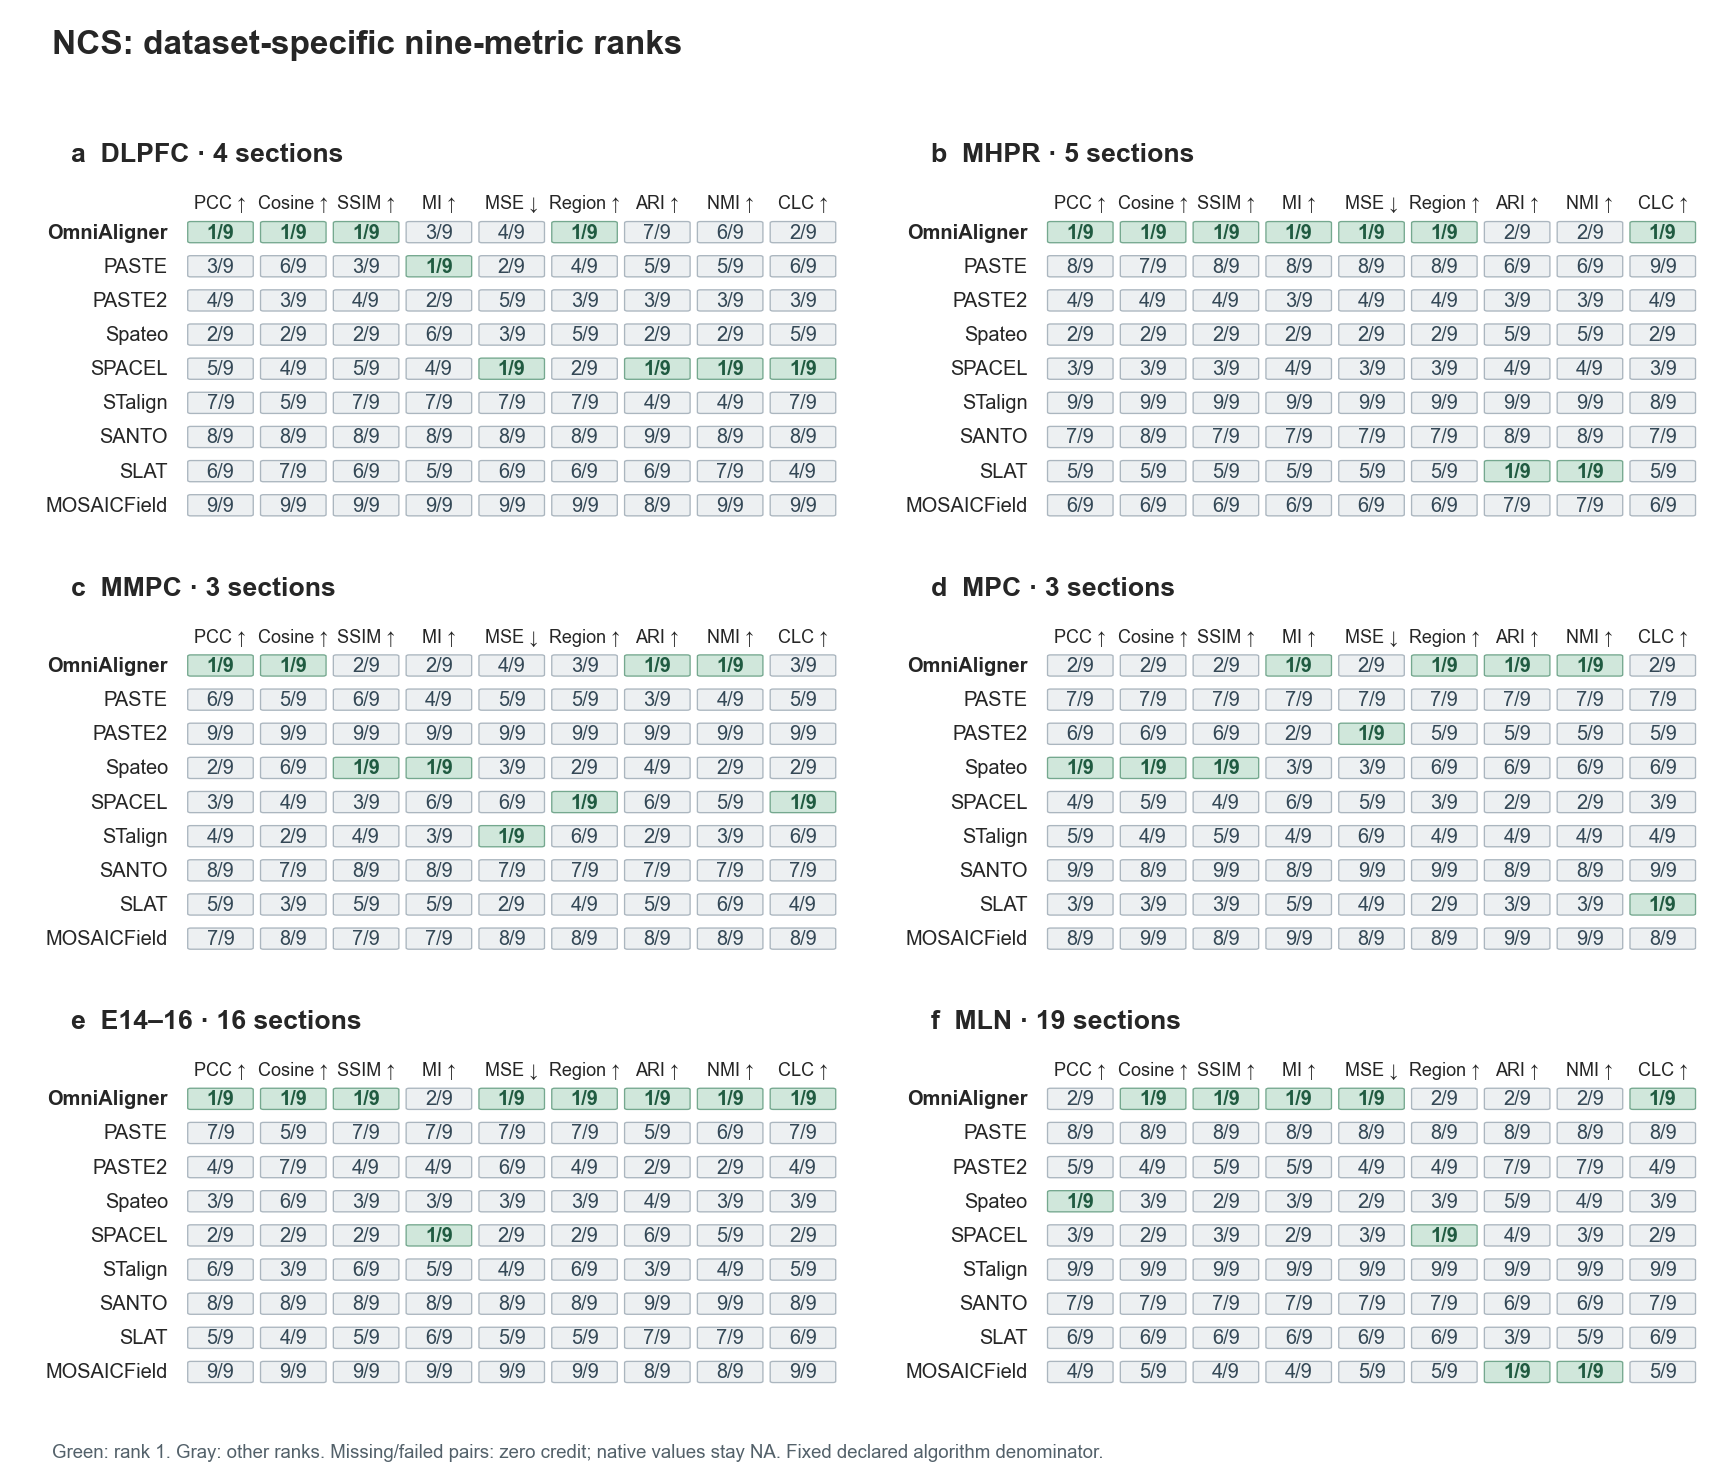

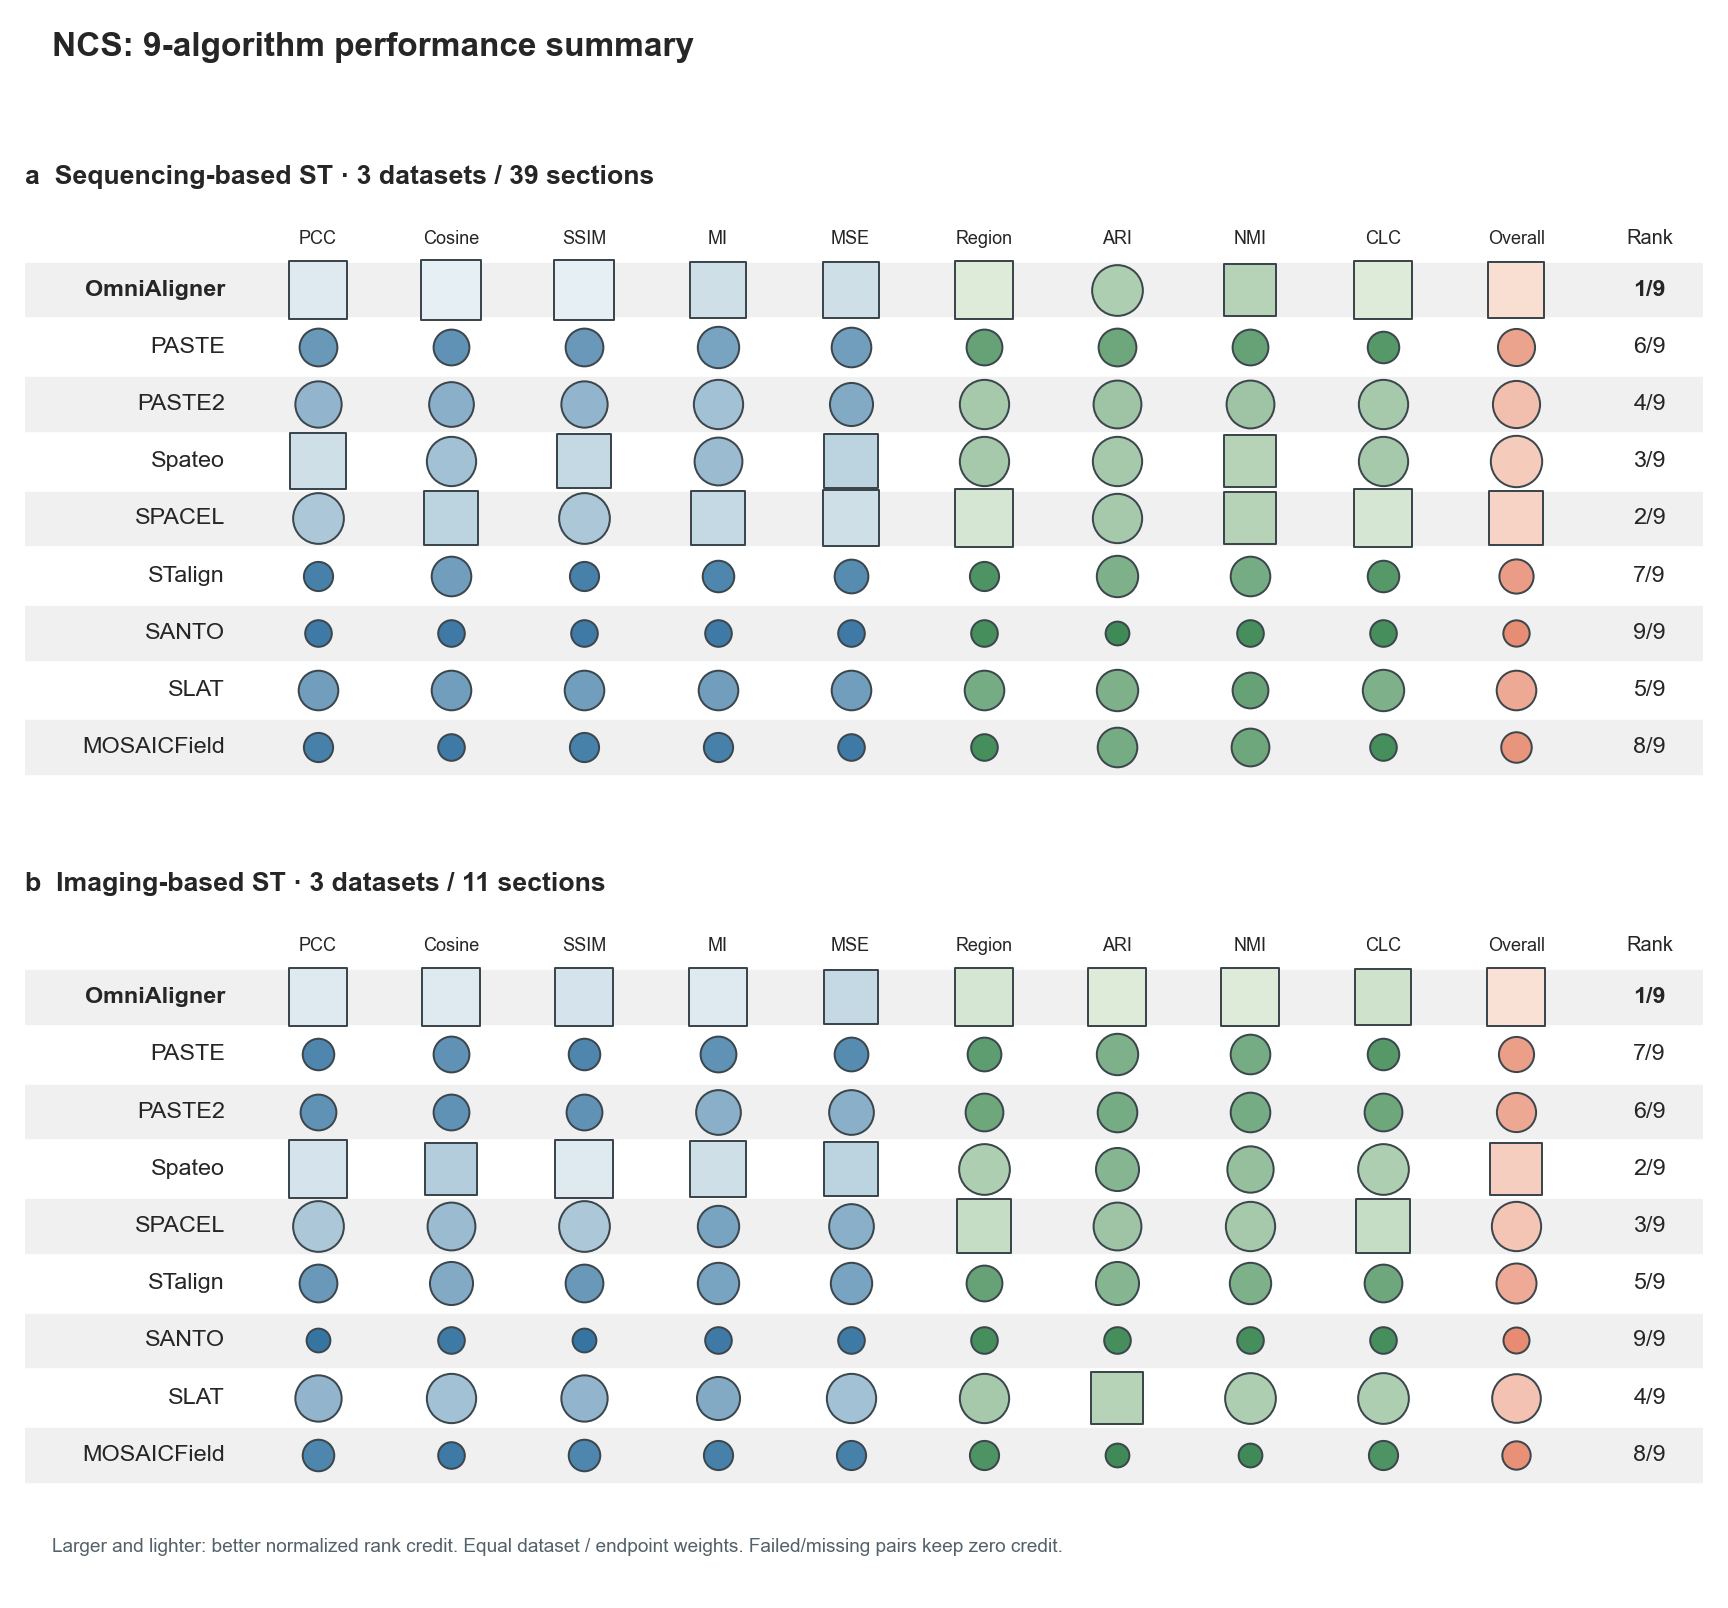

snapshot                                                                    8a91c856ca19edd6
scope                                      NCS: current source-bound pair scores; explici...
expected_pair_metric_positions                                                          3564
observed_eligible_pair_metric_positions                                                 3402
zero_credit_pair_metric_positions                                                        162
fresh_example_pairs                                                                        1
fresh_native_example_pairs                                                                 0
source_checksums_verified                                                               True
policy                                       expected_pair_weighted_native_metric_quality_v3
raw_missing_values_preserved                                                            True
no_partial_raw_mean_substitution                                      

In [24]:
CURRENT_OUTPUT = Path("ncs_reproduced")
CURRENT_OUTPUT.mkdir(exist_ok=True)
pair_scores.to_csv(CURRENT_OUTPUT / "pair_scores_and_coverage.csv", index=False)
endpoint_scores.to_csv(CURRENT_OUTPUT / "nine_metric_scores_and_ranks.csv", index=False)
wide_raw.to_csv(CURRENT_OUTPUT / "native_complete_means.csv")
wide_scores.to_csv(CURRENT_OUTPUT / "nine_metric_coverage_adjusted_quality.csv")
status.to_csv(CURRENT_OUTPUT / "condition_status.csv", index=False)
draw_current_figures(endpoint_scores, COHORTS, ALGORITHMS, ALL_METRICS, CURRENT_OUTPUT, 'NCS', complete=bool(current_manifest["all_tasks_complete"]))
current_validation = dict(snapshot=current_manifest["snapshot"],
    scope=current_manifest["scope"], expected_pair_metric_positions=len(pair_scores),
    observed_eligible_pair_metric_positions=int(pair_scores.eligible.sum()),
    zero_credit_pair_metric_positions=int(pair_scores.penalized.sum()),
    fresh_example_pairs=len(fresh_examples), fresh_native_example_pairs=len(globals().get("fresh_native_examples", [])), source_checksums_verified=True,
    policy="expected_pair_weighted_native_metric_quality_v3", raw_missing_values_preserved=True,
    no_partial_raw_mean_substitution=True, algorithm_roster=ALGORITHMS, fixed_algorithm_denominator=N_ALGORITHMS,
    all_tasks_complete=bool(current_manifest["all_tasks_complete"]),
    pdf_fonttype=om.pl.plt.rcParams["pdf.fonttype"],
    font_family=om.pl.plt.rcParams["font.family"])
(CURRENT_OUTPUT / "VALIDATION.json").write_text(json.dumps(current_validation, indent=2)+"\n")
display(pd.Series(current_validation))